<a href="https://colab.research.google.com/github/Adhityawarman03/Tugas_MetNum_Ketut-Adhityawarman/blob/main/Tugas_METNUM_Ketut_Adhityawarman_25083010029.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Baca data langsung dari link raw GitHub
url = "https://raw.githubusercontent.com/jendralhxr/metnummatdis/main/sintesis_data_donat_harian.csv"
df = pd.read_csv(url)

# Nampilin 5 baris awal untuk cek data
display(df.head())

# Nampilin daftar nama kolom
print("\nNama Kolom:", df.columns.tolist())

,Tanggal,Gerai,Harga Jual (Rp),Jumlah Terjual (Unit),Pendapatan Kotor (Rp),Biaya Variabel (Rp),Fixed Cost Harian (Rp),Balance (Rp)
0,2026-01-01,Gerai A,25000,87,2175000,739500,1683333,-247833
1,2026-01-02,Gerai A,25000,81,2025000,688500,1683333,-346833
2,2026-01-03,Gerai A,25000,110,2750000,935000,1683333,131667
3,2026-01-04,Gerai A,25000,119,2975000,1011500,1683333,280167
4,2026-01-05,Gerai A,25000,94,2350000,799000,1683333,-132333



Nama Kolom: ['Tanggal', 'Gerai', 'Harga Jual (Rp)', 'Jumlah Terjual (Unit)', 'Pendapatan Kotor (Rp)', 'Biaya Variabel (Rp)', 'Fixed Cost Harian (Rp)', 'Balance (Rp)']


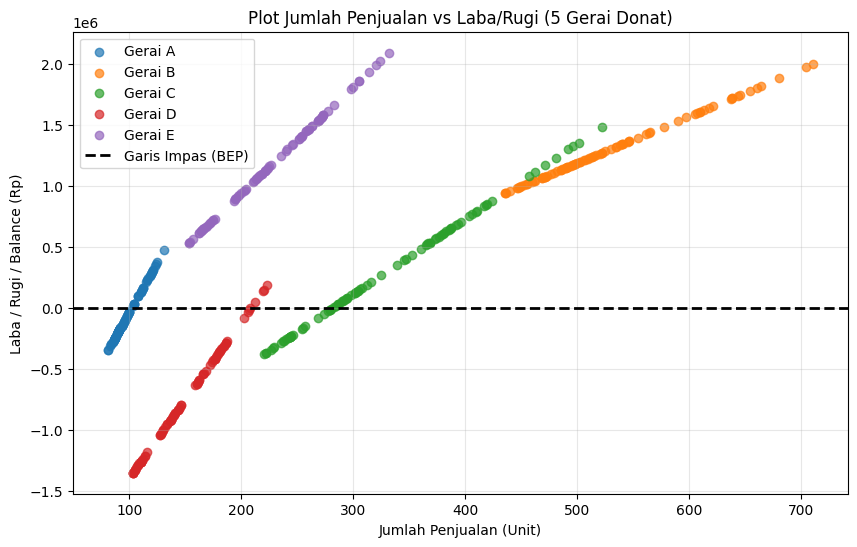

In [5]:
import matplotlib.pyplot as plt

# Setup ukuran kanvas grafik
plt.figure(figsize=(10, 6))

# Nama kolom yang sudah pasti benar
kolom_gerai = 'Gerai'
kolom_x = 'Jumlah Terjual (Unit)'
kolom_y = 'Balance (Rp)'

# Looping untuk menggambar titik data masing-masing gerai
daftar_gerai = df[kolom_gerai].unique()
for gerai in daftar_gerai:
    data_gerai = df[df[kolom_gerai] == gerai]
    # alpha=0.7 biar titiknya agak transparan kalau saling numpuk
    plt.scatter(data_gerai[kolom_x], data_gerai[kolom_y], label=gerai, alpha=0.7)

# Kustomisasi tampilan grafik
plt.title('Plot Jumlah Penjualan vs Laba/Rugi (5 Gerai Donat)')
plt.xlabel('Jumlah Penjualan (Unit)')
plt.ylabel('Laba / Rugi / Balance (Rp)')

# Bikin garis batas impas (Titik 0 / Breakeven Point)
plt.axhline(0, color='black', linestyle='--', linewidth=2, label='Garis Impas (BEP)')

# Nampilin legenda dan grid
plt.legend()
plt.grid(True, alpha=0.3)

# Munculkan grafik
plt.show()

=== HASIL ANALISIS REGRESI & BREAKEVEN POINT (BEP) ===

Gerai A:
 - Persamaan Regresi : y = 16500.00x + -1683333.00
 - Titik Impas (BEP) : Terjual 102 Unit

Gerai B:
 - Persamaan Regresi : y = 3840.00x + -733333.00
 - Titik Impas (BEP) : Terjual 191 Unit

Gerai C:
 - Persamaan Regresi : y = 6160.00x + -1733333.00
 - Titik Impas (BEP) : Terjual 281 Unit

Gerai D:
 - Persamaan Regresi : y = 12800.00x + -2666666.00
 - Titik Impas (BEP) : Terjual 208 Unit

Gerai E:
 - Persamaan Regresi : y = 8700.00x + -800000.00
 - Titik Impas (BEP) : Terjual 92 Unit


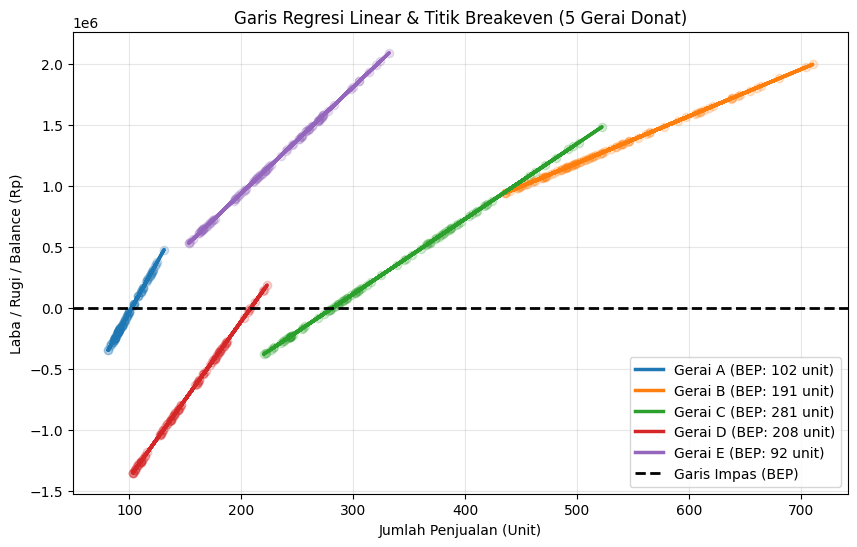

In [6]:


# Siapkan kanvas grafik baru
plt.figure(figsize=(10, 6))

print("=== HASIL ANALISIS REGRESI & BREAKEVEN POINT (BEP) ===")

# Looping untuk menghitung regresi tiap gerai
for gerai in daftar_gerai:
    data_gerai = df[df[kolom_gerai] == gerai]
    x = data_gerai[kolom_x]
    y = data_gerai[kolom_y]

    # 1. Regresi Linear (y = mx + c) pakai NumPy
    # m = gradien (profit per donat), c = intercept (minusnya fix cost)
    m, c = np.polyfit(x, y, 1)

    # 2. Pencarian Akar (Mencari nilai x saat y = 0)
    # Persamaan: 0 = mx + c  --->  x = -c / m
    bep_x = -c / m

    # Cetak hasil ke layar
    print(f"\n{gerai}:")
    print(f" - Persamaan Regresi : y = {m:.2f}x + {c:.2f}")
    print(f" - Titik Impas (BEP) : Terjual {bep_x:.0f} Unit")

    # Plot titik data asli (dibuat transparan)
    plt.scatter(x, y, alpha=0.2)
    # Plot garis regresi
    plt.plot(x, m*x + c, label=f"{gerai} (BEP: {bep_x:.0f} unit)", linewidth=2.5)

# Kustomisasi grafik regresi
plt.title('Garis Regresi Linear & Titik Breakeven (5 Gerai Donat)')
plt.xlabel('Jumlah Penjualan (Unit)')
plt.ylabel('Laba / Rugi / Balance (Rp)')
plt.axhline(0, color='black', linestyle='--', linewidth=2, label='Garis Impas (BEP)')
plt.legend()
plt.grid(True, alpha=0.3)

# Munculkan grafik
plt.show()